# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [39]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
import rioxarray as rioxr 

In [40]:
pwd

'/Users/natashaclemencon/Documents/Git/EDS-220/eds220-in-class'

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [41]:
# Import NIR TIF file
fp = os.path.join(
                  'data',
                  'rioxarray_lesson_data', 'NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir


<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [42]:
# Access attributes directly
print('Shape: ', nir.shape)
print('Data type: ', nir.dtype)

Shape:  (1, 3208, 2419)
Data type:  uint8


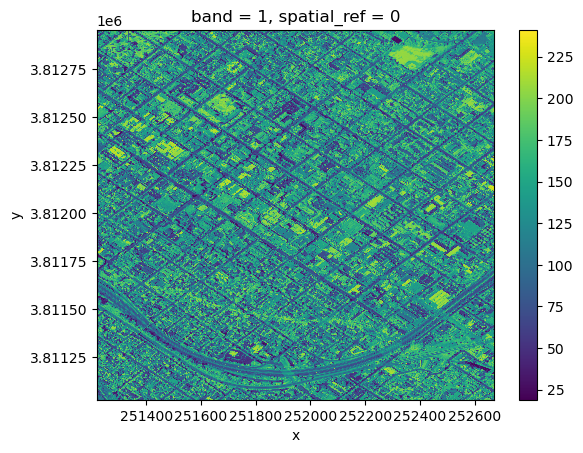

In [43]:
nir.plot()

# Drop a dimension

The raster has an unnecessary extra dimension: band.

In [44]:
print('Sizes of dimensions:' , dict(nir.sizes))

Sizes of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


- `band` has length 1, so it makes the `xarray 3d for no reason
- `squeeze` removes a dimensino of length 1
- `drop=True` remove the coordinates for that dimension

In [45]:
# Original dimensions and coordinates
print(nir.dims, nir.coords, '\n')

# Remove length 1 dimension (band) and its coordinates
nir.squeeze('band', drop=True)

print(nir.dims, nir.coords, '\n')

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



## `rio` accessor


In [46]:
# Examine raster attributes using rio accessor
print('Number of bands: ', nir.rio.count)
print('Height:', nir.rio.height)
print('Width:', nir.rio.width, '\n')

print('CRS:', nir.rio.crs, '\n')

print('Spatial bounding box:')
print(nir.rio.bounds())

Number of bands:  1
Height: 3208
Width: 2419 

CRS: EPSG:26911 

Spatial bounding box:
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


In [47]:
# Import RGB raster
fp = os.path.join(
                  'data',
                  'rioxarray_lesson_data', 'NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Check in:
Obtain this information: shape, number of bands, dtype, and CRS

In [48]:
print('Shape: ', nir.shape)
print('Data type: ', nir.dtype)
print('Number of bands: ', nir.rio.count)
print('CRS:', nir.rio.crs)


Shape:  (1, 3208, 2419)
Data type:  uint8
Number of bands:  1
CRS: EPSG:26911


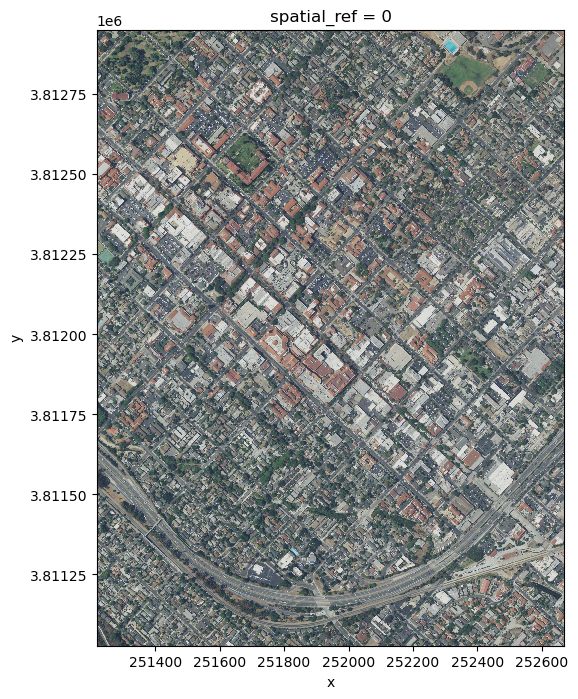

In [49]:
# Plot three bands as RGB image
rgb_aspect_ratio = rgb.rio.width/rgb.rio.height # Raster's aspect ratio
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio,8 ))

## Clip raster 

Our AOI is a few blocks around the NCEAS building, outlined in a GeoJSON file:

<Axes: >

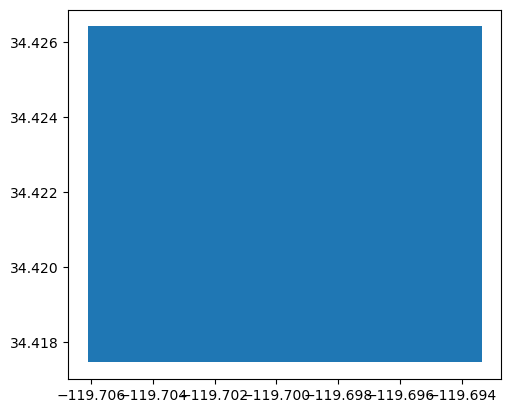

In [50]:
fp = os.path.join(
                  'data',
                  'rioxarray_lesson_data', 'SB_aoi.geojson')
aoi = gpd. read_file(fp)
aoi.plot()

In [51]:
# Examine the CRSs
print('aoi CRS:', aoi.crs)
print('nir CRS:', nir.rio.crs)
print('rgb CRS:', rgb.rio.crs)

aoi CRS: EPSG:4326
nir CRS: EPSG:26911
rgb CRS: EPSG:26911


In [52]:
# Reproject AOI to RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

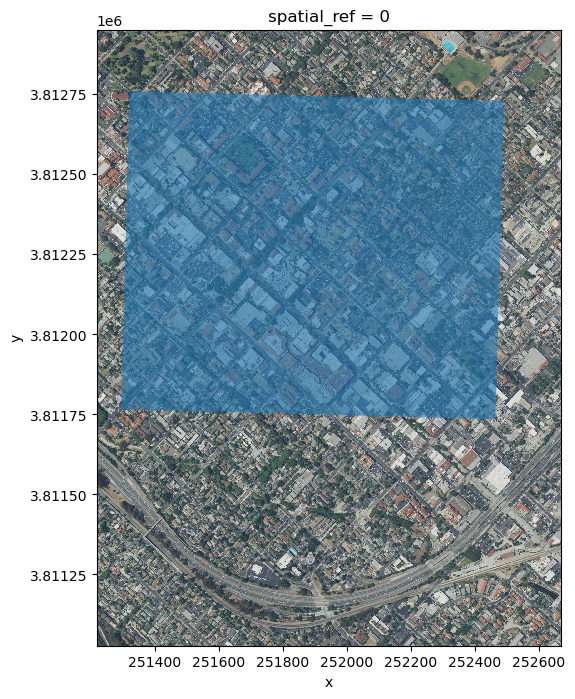

In [53]:
# Plot of RGB raster with AOI overlay
fig, ax = plt.subplots(figsize=(8 * rgb_aspect_ratio, 8))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha=0.6)
plt.show()

In [54]:
# Clip rasters to AOI
rgb_small = rgb.rio.clip_box(*aoi.total_bounds)
nir_small = nir.rio.clip_box(*aoi.total_bounds)

In [55]:
# Examine clipped data 
print('Original shape:', nir.shape)
print('Clipped shape:', nir_small.shape)


Original shape: (1, 3208, 2419)
Clipped shape: (1, 1710, 1995)


# Raster math 
We will compute the **Normalized Difference Vegetation Infex (NDVI)** over our AOI. 

NDVI checks whether an area has live green vegetation. 

NDVI is always between -1 and 1: values above 0.6 correspond to bright green lush vegetation. Water, roofs, pavement, close to 0 or negative. Sand, rock, snow, 0.1 and below. Generally about 0.1 is vegetation. 

NDVI uses NIR and red bands: 

$$NDVI = \frac{NIR-Red}{NIRD+Red}$$

In [56]:
# Select dimension by name and coordinate by label 
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [57]:
ndvi = (nir_small - red_small)/(nir_small+red_small)
ndvi

<xarray.DataArray (band: 1, y: 1710, x: 1995)> Size: 27MB
array([[[           inf, 3.37500000e+00, 9.25000000e+00, ...,
         5.85000000e+01, 1.18811881e+00, 2.46913580e-02],
        [2.93650794e-01,            inf, 2.88888889e+00, ...,
         3.50000000e+00, 2.35000000e+02, 6.54205607e-02],
        [3.20158103e-01, 3.23076923e-01, 3.49112426e-01, ...,
         4.32203390e+00, 1.66666667e-01, 5.28571429e+00],
        ...,
        [3.96039604e-02, 1.06779661e+00, 9.76470588e-01, ...,
         3.63492063e+00, 4.22222222e+00, 8.70370370e+00],
        [1.06521739e+01, 9.92156863e-01, 8.06451613e-03, ...,
         4.10714286e+00, 3.69696970e+00, 2.14018692e+00],
        [1.10869565e+01, 6.83783784e+00, 0.00000000e+00, ...,
         3.93750000e+00, 1.95934959e+00, 1.51282051e+00]]])
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0

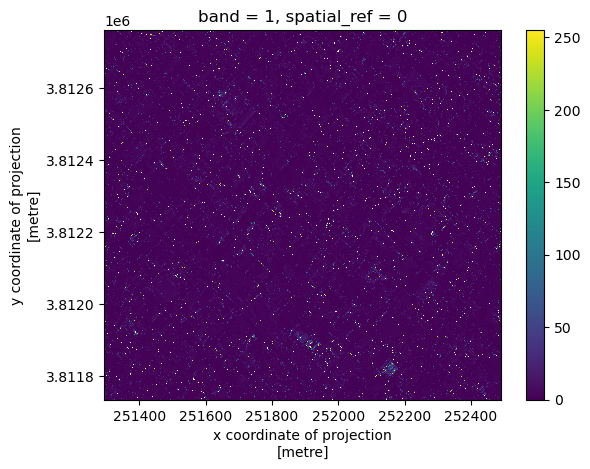

In [58]:
ndvi.plot()

## Data type issues


In [59]:
nir_small


<xarray.DataArray (band: 1, y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

We can see the data type for the raster is `uint8` = 8-bit unsigned integer = only holds integers from 0-255.
Calculations wrap around (module 256)

In [60]:
150+150

300

In [61]:
np.uint8(150) + np.uint8(150)

/var/folders/2y/6h2sr1_n2xvd_zrgh7n38jj80000gn/T/ipykernel_26763/1890984988.py:1: RuntimeWarning: overflow encountered in scalar add
  np.uint8(150) + np.uint8(150)


44

** Avoid silent failures! Always verify your results **
We will fix this by updating the data types

In [62]:
# Update data type to int16 to perform NDVI calculations
red16 = red_small.astype('int16')
nir16 = nir_small.astype('int16')

print('RED: original dtype:', rgb_small.dtype, '... converted dtype:', red16.dtype)
print('NIR: original dtype:', nir_small.dtype, '... converted dtype:', nir16.dtype)

RED: original dtype: uint8 ... converted dtype: int16
NIR: original dtype: uint8 ... converted dtype: int16


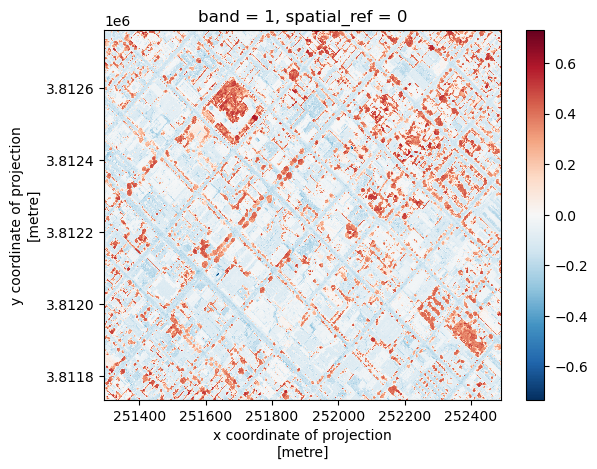

In [63]:
# Calculate NDVI
ndvi = (nir16 - red16)/(nir16 + red16)

# Plot 
ndvi.plot()